# Solutions to notebook 16: Capstone: pipe flow of a Carreau–Yasuda fluid

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/solutions/16_capstone_carreau_yasuda.ipynb)

Worked solutions to the exercises at the end of [notebook 16](../notebooks/16_capstone_carreau_yasuda.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import cumulative_trapezoid, quad
from scipy.optimize import brentq
from scipy.special import hyp2f1

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## The solution of the lesson, rebuilt

The exercises build on the analytical solution of notebook 16. The next three cells repeat it
without commentary: the fluid model (16.1), the scaled velocity and average velocity (16.3 to
16.5), and the numerical functions with `solve_pipe` (16.7).

In [2]:
gamma_dot = sp.symbols("gammadot", positive=True)
eta_0, eta_inf, lam, a, n = sp.symbols("eta_0 eta_inf lambda a n", positive=True)

eta = eta_inf + (eta_0 - eta_inf) * (1 + (lam * gamma_dot) ** a) ** ((n - 1) / a)

fluid = dict(eta0=1400.0, etainf=0.0, lam=1.6, n=0.2, a=1.25)      # Pa·s, Pa·s, s, -, -
viscosity = sp.lambdify((gamma_dot, eta_0, eta_inf, lam, n, a), eta, "numpy")

def eta_of(rate, f=fluid):
    return viscosity(rate, f["eta0"], f["etainf"], f["lam"], f["n"], f["a"])

In [3]:
s, xi = sp.symbols("s xi", positive=True)
Lam = sp.symbols("Lambda", positive=True)
e0, einf = sp.symbols("etatilde_0 etatilde_inf", nonnegative=True)       # η₀/η_w and η∞/η_w

def shear_thinning(z):
    """The factor [1 + (Λ z)^a]^((n-1)/a), which carries all the non-Newtonian behaviour."""
    return (1 + (Lam * z) ** a) ** ((n - 1) / a)

def eta_tilde(z):
    return einf + (e0 - einf) * shear_thinning(z)

def tidy(expr):
    """Cancel the gamma functions and write exp_polar(iπ) as -1."""
    return sp.gammasimp(expr).replace(sp.exp_polar, sp.exp)

r_tilde = s * eta_tilde(s)
half_Phi = tidy(sp.integrate(xi * shear_thinning(xi), (xi, 0, s)))

def antiderivative(z):                                   # of ξ·η̃(ξ)
    return einf * z**2 / 2 + (e0 - einf) * half_Phi.subs(s, z)

u_tilde = 1 - s * r_tilde - (antiderivative(1) - antiderivative(s))
u_max_tilde = 1 - antiderivative(1)

I = {k: tidy(sp.integrate(s**3 * shear_thinning(s) ** k, (s, 0, 1))) for k in (1, 2, 3)}
d = e0 - einf
integral_r_cubed = einf**3 / 4 + 3 * einf**2 * d * I[1] + 3 * einf * d**2 * I[2] + d**3 * I[3]
u_avg_tilde = (1 - integral_r_cubed) / 3
half_Phi

        ⎛2  -(n - 1)  │       ⎞
        ⎜─, ───────── │       ⎟
 2  ┌─  ⎜a      a     │   a  a⎟
s ⋅ ├─  ⎜             │ -Λ ⋅s ⎟
   2╵ 1 ⎜   a + 2     │       ⎟
        ⎜   ─────     │       ⎟
        ⎝     a       │       ⎠
───────────────────────────────
               2               

In [4]:
translation = [{"hyper": lambda upper, lower, z: hyp2f1(upper[0], upper[1], lower[0], z)}, "numpy"]
arguments = (Lam, e0, einf, n, a)

r_fun = sp.lambdify((s, *arguments), r_tilde, translation)
u_fun = sp.lambdify((s, *arguments), u_tilde, translation)
u_max_fun = sp.lambdify(arguments, u_max_tilde, translation)
u_avg_fun = sp.lambdify(arguments, u_avg_tilde, translation)

def solve_pipe(G, R, f=fluid):
    """Wall shear rate, velocities and flow rate for pressure gradient G (Pa/m) and radius R (m)."""
    tau_wall = G * R / 2
    gamma_wall = brentq(lambda rate: eta_of(rate, f) * rate - tau_wall, tau_wall / f["eta0"] * 0.5, 1e12)
    eta_wall = eta_of(gamma_wall, f)
    reduced = (f["lam"] * gamma_wall, f["eta0"] / eta_wall, f["etainf"] / eta_wall, f["n"], f["a"])
    scale = R * gamma_wall                                 # velocity scale
    u_max, u_avg = scale * u_max_fun(*reduced), scale * u_avg_fun(*reduced)
    return dict(gamma_wall=gamma_wall, eta_wall=eta_wall, reduced=reduced, scale=scale,
                u_max=u_max, u_avg=u_avg, Q=np.pi * R**2 * u_avg, ratio=u_max / u_avg)

R_tube = 0.01                                              # m
result = solve_pipe(G=0.6e6, R=R_tube)                     # 0.6 MPa/m

# the rebuilt solution reproduces the published values quoted in 16.7
published = dict(gamma_wall=296.5, u_max=0.500, u_avg=0.372, Q=1.169e-4, ratio=1.343)
for key, value in published.items():
    assert abs(result[key] / value - 1) < 1e-3, key

## Exercise 1

For the Carreau model ($a = 2$) the velocity integral is elementary. Evaluate
$\int_0^s \xi\,[1 + (\Lambda\xi)^2]^{(n-1)/2}\,d\xi$ with SymPy and confirm numerically that
it equals $\tfrac12\Phi(s)$ at $a = 2$.

In [5]:
carreau_integrand = xi * (1 + (Lam * xi) ** 2) ** ((n - 1) / 2)
carreau_integral = sp.simplify(sp.integrate(carreau_integrand, (xi, 0, s)))
carreau_integral

           n   1    
           ─ + ─    
           2   2    
⎛ 2  2    ⎞         
⎝Λ ⋅s  + 1⎠      - 1
────────────────────
      2             
     Λ ⋅(n + 1)     

In [6]:
# verify by hand: with w = 1 + (Λξ)² the integrand is w^((n-1)/2) dw / (2Λ²), a plain power
by_hand = ((1 + (Lam * s) ** 2) ** ((n + 1) / 2) - 1) / ((n + 1) * Lam**2)
assert sp.simplify(carreau_integral - by_hand) == 0
# verify by differentiation: the derivative is the integrand, and the integral vanishes at s = 0
assert sp.simplify(carreau_integral.diff(s) - carreau_integrand.subs(xi, s)) == 0
assert sp.limit(carreau_integral, s, 0) == 0

Now the comparison with the hypergeometric form. At $a = 2$,
$\tfrac12\Phi(s) = \tfrac12 s^2\,{}_2F_1\!\left(1, \tfrac{1-n}{2}; 2; -(\Lambda s)^2\right)$.

In [7]:
half_Phi_carreau = half_Phi.subs(a, 2)
half_Phi_carreau

        ⎛   1   n │       ⎞
 2  ┌─  ⎜1, ─ - ─ │   2  2⎟
s ⋅ ├─  ⎜   2   2 │ -Λ ⋅s ⎟
   2╵ 1 ⎜         │       ⎟
        ⎝   2     │       ⎠
───────────────────────────
             2             

In [8]:
elementary_fun = sp.lambdify((s, Lam, n), carreau_integral, "numpy")
hypergeometric_fun = sp.lambdify((s, Lam, n), half_Phi_carreau, translation)

s_values = np.linspace(0.01, 1, 100)
worst = 0.0
for Lam_value in (0.1, 1.0, 10.0, 100.0):
    for n_value in (0.2, 0.5, 0.8, 1.5):
        difference = hypergeometric_fun(s_values, Lam_value, n_value) / elementary_fun(s_values, Lam_value, n_value) - 1
        worst = max(worst, np.abs(difference).max())
print(f"largest relative difference over 1600 combinations of s, Λ and n: {worst:.1e}")
# The largest differences occur at the smallest Λs, and they come from the elementary formula:
# it subtracts two nearly equal numbers there, which costs about six of the sixteen digits.
assert worst < 1e-9

# one point to 30 digits, with SymPy's own arbitrary-precision evaluation of the hypergeometric function
point = {s: sp.Rational(3, 5), Lam: sp.Rational(7, 3), n: sp.Rational(1, 5)}
assert abs(sp.N((half_Phi_carreau - carreau_integral).subs(point), 30)) < 1e-25

largest relative difference over 1600 combinations of s, Λ and n: 1.6e-10


**Answer.**

$$\int_0^s \xi\left[1 + (\Lambda\xi)^2\right]^{(n-1)/2}d\xi
= \frac{\left[1 + (\Lambda s)^2\right]^{(n+1)/2} - 1}{(n+1)\,\Lambda^2} .$$

It agrees with $\tfrac12\Phi(s)$ at $a = 2$ to better than one part in $10^9$ for all values
tried, and to 30 digits at the test point. The small remaining differences are rounding error
in the elementary formula at small $\Lambda s$, where it subtracts nearly equal numbers. For the Carreau model the hypergeometric function in the velocity
profile therefore reduces to a power, and the profile is elementary. The average velocity still
needs the hypergeometric integrals of 16.5.

## Exercise 2

Give the example fluid a high-shear plateau, $\eta_\infty = 1$ Pa·s. Plot $u_{max}/u_{avg}$
against $G$ from $10^2$ to $10^{10}$ Pa/m. Explain why the ratio returns to 2.

`solve_pipe` takes the fluid as an argument, and the formulas of 16.4 and 16.5 already contain
$\tilde\eta_\infty$, so only the parameter changes.

In [9]:
plateau_fluid = dict(fluid, etainf=1.0)

G_wide = np.logspace(2, 10, 161)
plateau_sweep = [solve_pipe(G, R_tube, plateau_fluid) for G in G_wide]
plateau_ratios = np.array([res["ratio"] for res in plateau_sweep])

G_lesson = np.logspace(2, 6.5, 80)                         # the range of 16.8, for the fluid without plateau
lesson_ratios = np.array([solve_pipe(G, R_tube)["ratio"] for G in G_lesson])
power_law_ratio = (3 * fluid["n"] + 1) / (fluid["n"] + 1)

lowest = plateau_ratios.argmin()
print(f"ratio at G = 1e2: {plateau_ratios[0]:.4f}    at G = 1e10: {plateau_ratios[-1]:.4f}")
print(f"lowest ratio {plateau_ratios[lowest]:.3f} at G = {G_wide[lowest]:.2g} Pa/m    (power law: {power_law_ratio:.3f})")

ratio at G = 1e2: 2.0000    at G = 1e10: 1.9994
lowest ratio 1.376 at G = 5.6e+05 Pa/m    (power law: 1.333)


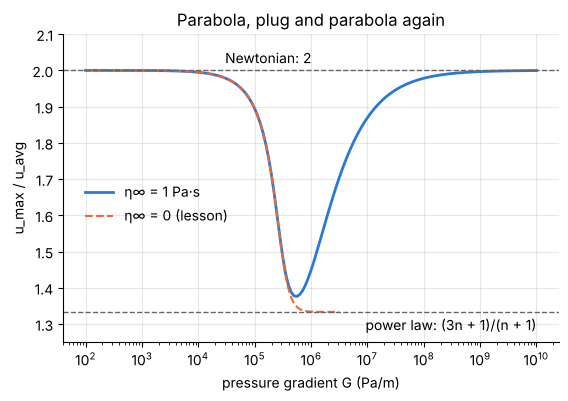

In [10]:
fig, ax = plt.subplots()
ax.semilogx(G_wide, plateau_ratios, label="η∞ = 1 Pa·s")
ax.semilogx(G_lesson, lesson_ratios, ls="--", lw=1.5, label="η∞ = 0 (lesson)")
ax.axhline(2, color="0.4", lw=1, ls="--")
ax.axhline(power_law_ratio, color="0.4", lw=1, ls="--")
ax.annotate("Newtonian: 2", xy=(3e4, 2), xytext=(3e4, 2.02))
ax.annotate("power law: (3n + 1)/(n + 1)", xy=(1e10, power_law_ratio), xytext=(1e10, power_law_ratio - 0.05), ha="right")
ax.set(xlabel="pressure gradient G (Pa/m)", ylabel="u_max / u_avg", ylim=(1.25, 2.1),
       title="Parabola, plug and parabola again")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(0.02, 0.45));

**Verify.** This is the first time the terms with $\tilde\eta_\infty$, and with them the
integrals $I_1$ and $I_2$ of 16.5, are actually used, so check them against plain numerical
quadrature of equations (2) and (3): $\tilde u_{max} = 1 - \int_0^1 \tilde r\,ds$ and
$\tilde u_{avg} = \tfrac13\left[1 - \int_0^1 \tilde r^{\,3}ds\right]$. No hypergeometric
functions are involved. The flow rate at the highest $G$ should also approach the
Hagen–Poiseuille value for a Newtonian fluid of viscosity $\eta_\infty$.

In [11]:
r_plain = sp.lambdify((s, *arguments), r_tilde, "numpy")
breakpoints = np.logspace(-9, -1, 9)                       # help quad find the thin Newtonian core near s = 0

def ratio_by_quadrature(reduced):
    integral_r = quad(lambda z: r_plain(z, *reduced), 0, 1, points=breakpoints, limit=400, epsabs=1e-13, epsrel=1e-12)[0]
    integral_r3 = quad(lambda z: r_plain(z, *reduced) ** 3, 0, 1, points=breakpoints, limit=400, epsabs=1e-13, epsrel=1e-12)[0]
    return (1 - integral_r) / ((1 - integral_r3) / 3)

for index in range(0, len(G_wide), 16):
    assert abs(plateau_ratios[index] / ratio_by_quadrature(plateau_sweep[index]["reduced"]) - 1) < 1e-9

Q_poiseuille = np.pi * G_wide[-1] * R_tube**4 / (8 * plateau_fluid["etainf"])
print(f"G = 1e10 Pa/m: wall viscosity {plateau_sweep[-1]['eta_wall']:.4f} Pa·s, "
      f"Q / (Hagen–Poiseuille with η∞) = {plateau_sweep[-1]['Q'] / Q_poiseuille:.4f}")
assert abs(plateau_sweep[-1]["Q"] / Q_poiseuille - 1) < 5e-3
assert abs(plateau_ratios[0] - 2) < 1e-3 and abs(plateau_ratios[-1] - 2) < 1e-3
assert power_law_ratio < plateau_ratios.min() < 1.4

G = 1e10 Pa/m: wall viscosity 1.0007 Pa·s, Q / (Hagen–Poiseuille with η∞) = 0.9992


**Answer.** The ratio falls from 2 to a minimum of about 1.38 near $G = 6\times10^5$ Pa/m and
then climbs back to 2. At very high shear rates the shear-thinning term has died away and the
viscosity is the constant $\eta_\infty$. When the pressure gradient is large enough, almost the
whole cross-section is in that second Newtonian regime (only a thin core around the axis, where
the shear rate is low, is not), so the profile is a parabola again and the flow rate follows
Hagen–Poiseuille with $\eta_\infty$. The power-law value $4/3$ is never reached, because the
plateau takes over before the power-law regime fills the tube.

## Exercise 3

Capillary rheometers report the apparent wall shear rate $\dot\gamma_a = 4Q/(\pi R^3)$,
which is exact only for a Newtonian fluid. The Weissenberg–Rabinowitsch correction is
$\dot\gamma_w = \dfrac{\dot\gamma_a}{4}\left(3 + \dfrac{d\ln\dot\gamma_a}{d\ln\tau_w}\right)$.
Verify it numerically for the example fluid over the range of $G$ used in 16.8.

The radius is fixed, so $\tau_w = GR/2$ is proportional to $G$ and
$d\ln\tau_w = d\ln G$. The slope is taken as a central difference with a small step in $\ln G$,
which is more accurate than differencing the 80 widely spaced points of the sweep.

In [12]:
def apparent_rate(G):
    return 4 * solve_pipe(G, R_tube)["Q"] / (np.pi * R_tube**3)

step = 1e-4                                                # relative step in G
G_values = np.logspace(2, 6.5, 80)                         # the range of 16.8
gamma_apparent = np.array([apparent_rate(G) for G in G_values])
log_slope = np.array([np.log(apparent_rate(G * (1 + step)) / apparent_rate(G * (1 - step))) for G in G_values]) \
            / np.log((1 + step) / (1 - step))
gamma_corrected = gamma_apparent / 4 * (3 + log_slope)     # Weissenberg–Rabinowitsch
gamma_true = np.array([solve_pipe(G, R_tube)["gamma_wall"] for G in G_values])     # from the root finder

mismatch = np.abs(gamma_corrected / gamma_true - 1).max()
print(f"largest relative difference between corrected and true wall shear rate: {mismatch:.1e}")
print(f"log-slope runs from {log_slope[0]:.4f} to {log_slope[-1]:.4f};  1/n = {1 / fluid['n']:g}")
print(f"true / apparent wall shear rate runs from {gamma_true[0] / gamma_apparent[0]:.4f} to {gamma_true[-1] / gamma_apparent[-1]:.4f}")
assert mismatch < 1e-6
# limits: slope 1 and no correction for a Newtonian fluid, slope 1/n and factor (3n + 1)/(4n) for a power law
assert abs(log_slope[0] - 1) < 1e-3 and abs(log_slope[-1] - 1 / fluid["n"]) < 1e-3
assert abs(gamma_true[-1] / gamma_apparent[-1] - (3 * fluid["n"] + 1) / (4 * fluid["n"])) < 1e-3

largest relative difference between corrected and true wall shear rate: 4.0e-09
log-slope runs from 1.0001 to 5.0000;  1/n = 5
true / apparent wall shear rate runs from 1.0000 to 2.0000


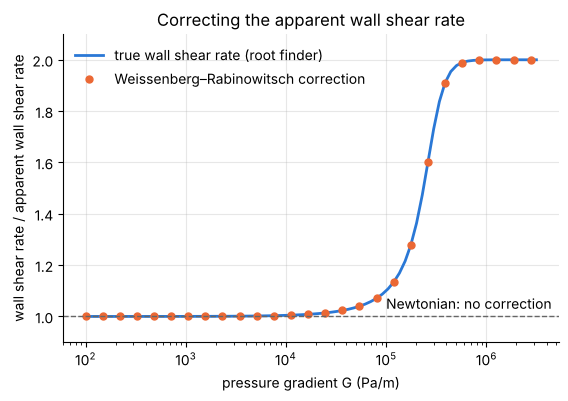

In [13]:
fig, ax = plt.subplots()
ax.semilogx(G_values, gamma_true / gamma_apparent, label="true wall shear rate (root finder)")
ax.semilogx(G_values[::3], (gamma_corrected / gamma_apparent)[::3], "o", ms=5, label="Weissenberg–Rabinowitsch correction")
ax.axhline(1, color="0.4", lw=1, ls="--")
ax.annotate("Newtonian: no correction", xy=(1e5, 1), xytext=(1e5, 1.03))
ax.set(xlabel="pressure gradient G (Pa/m)", ylabel="wall shear rate / apparent wall shear rate", ylim=(0.9, 2.1),
       title="Correcting the apparent wall shear rate")
ax.legend(frameon=False, loc="upper left");

**Answer.** The corrected value agrees with the wall shear rate found by `solve_pipe` to better
than one part in $10^6$ over the whole range, limited only by the finite-difference slope. The
correction factor $\dot\gamma_w/\dot\gamma_a$ rises from 1 in the Newtonian regime (log-slope 1)
to $(3n+1)/(4n) = 2$ in the power-law regime (log-slope $1/n = 5$). Using the apparent shear
rate for this fluid would underestimate the true wall value by up to a factor of two.

## Exercise 4

Repeat the derivation for pressure-driven flow between parallel plates a distance $2h$ apart,
where $\tau = G\,y$. Show that $\tilde u(s)$ is unchanged and that
$\tilde u_{avg} = \tfrac12\left[1 - \int_0^1 \tilde y(s)^2\,ds\right]$, and evaluate the
integral with SymPy for $\eta_\infty = 0$.

**Scaling.** With $y$ measured from the mid-plane, $\eta(\dot\gamma)\,\dot\gamma = G\,y$ and at
the wall $\eta_w\dot\gamma_w = G\,h$. Dividing, with $\tilde y = y/h$ and
$\tilde u = u/(h\dot\gamma_w)$, gives $\tilde y(s) = s\,\tilde\eta(s)$: the same relation as
$\tilde r(s)$ in the pipe. Also $d\tilde u/d\tilde y = -s$ with $\tilde u = 0$ at $s = 1$, exactly
as in 16.4. So equation (2) holds with $\tilde y$ in place of $\tilde r$, and $\tilde u(s)$ is
unchanged. Only the wall condition differs: $\tau_w = Gh$ instead of $GR/2$.

**Average.** The area element is now $d\tilde y$ instead of $2\tilde r\,d\tilde r$, so
$\tilde u_{avg} = \int_0^1 \tilde u\,d\tilde y = \int_0^1 \tilde u\,\tilde y'(s)\,ds$.
Integrating by parts twice, as in 16.5,

$$\tilde u_{avg} = \int_0^1 \tilde y\,s\,d\tilde y
= \frac12\left[1 - \int_0^1 \tilde y(s)^2\,ds\right].$$

**Check with SymPy, for any viscosity function.** Let $W(s) = \tilde u\,\tilde y + \tfrac12 s\,\tilde y^2$.
If $W' = \tilde u\,\tilde y' + \tfrac12\tilde y^2$, then integrating from 0 to 1 gives
$\tilde u_{avg} + \tfrac12\int_0^1\tilde y^2 ds = W(1) - W(0)$, and the result follows from
$W(1) = \tfrac12$ and $W(0) = 0$.

In [14]:
any_eta = sp.Function("etatilde")
y_generic = s * any_eta(s)
u_generic = 1 - s * y_generic - sp.Integral(xi * any_eta(xi), (xi, s, 1))      # equation (2)

assert sp.simplify(u_generic.diff(s) + s * y_generic.diff(s)) == 0             # dũ = -s dỹ, as in the pipe
assert u_generic.subs(s, 1).doit().subs(any_eta(1), 1) == 0                    # no slip

W = u_generic * y_generic + s * y_generic**2 / 2
assert sp.simplify(W.diff(s) - (u_generic * y_generic.diff(s) + y_generic**2 / 2)) == 0
assert W.subs(s, 1).doit().subs(any_eta(1), 1) == sp.Rational(1, 2)
assert W.subs(s, 0) == 0

**The integral for $\eta_\infty = 0$.** Then $\tilde y = \tilde\eta_0\,s\,X(s)$ with $X$ the
shear-thinning factor, and one hypergeometric integral is needed.

In [15]:
J = tidy(sp.integrate(s**2 * shear_thinning(s) ** 2, (s, 0, 1)))
u_avg_plates = (1 - e0**2 * J) / 2
u_max_plates = u_max_tilde.subs(einf, 0)                 # the centreline value of ũ is the same as in the pipe
J

     ⎛3  -2⋅(n - 1)  │    ⎞
     ⎜─, ─────────── │    ⎟
 ┌─  ⎜a       a      │   a⎟
 ├─  ⎜               │ -Λ ⎟
2╵ 1 ⎜    a + 3      │    ⎟
     ⎜    ─────      │    ⎟
     ⎝      a        │    ⎠
───────────────────────────
             3             

In [16]:
# verify the special function: derivative of the s-dependent antiderivative, to 30 digits at a point
J_of_s = tidy(sp.integrate(xi**2 * shear_thinning(xi) ** 2, (xi, 0, s)))
point = {s: sp.Rational(3, 5), Lam: sp.Rational(7, 3), a: sp.Rational(5, 4), n: sp.Rational(1, 5)}
assert abs(sp.N((J_of_s.diff(s) - s**2 * shear_thinning(s) ** 2).subs(point), 30)) < 1e-25
assert sp.simplify(J_of_s.subs(s, 1) - J) == 0

# Newtonian limit: mean velocity two thirds of the maximum (notebook 6, exercise 3)
newtonian = {n: 1, e0: 1}
assert sp.hyperexpand(u_avg_plates.subs(newtonian)) == sp.Rational(1, 3)
assert sp.hyperexpand(u_avg_plates.subs(newtonian)) / sp.hyperexpand(u_max_plates.subs(newtonian)) == sp.Rational(2, 3)

# power-law limit: ỹ = s^n, and the textbook ratio u_max / u_avg = (2n + 1)/(n + 1)
u_max_pl = 1 - sp.integrate(xi * xi ** (n - 1), (xi, 0, 1))
u_avg_pl = (1 - sp.integrate(s ** (2 * n), (s, 0, 1))) / 2
assert sp.simplify(u_max_pl / u_avg_pl - (2 * n + 1) / (n + 1)) == 0
sp.simplify(u_avg_pl)

   n   
───────
2⋅n + 1

**Numbers, and a brute-force check.** Take the example fluid between plates with $h = 10$ mm and
$G = 0.3$ MPa/m, which gives the same wall shear stress, 3000 Pa, as the pipe of 16.7. As in 16.7, compare with a calculation that uses none of the analysis: solve
$\eta(\dot\gamma)\dot\gamma = Gy$ at every grid point and integrate with the trapezoidal rule.

In [17]:
u_max_plates_fun = sp.lambdify((Lam, e0, n, a), u_max_plates, translation)
u_avg_plates_fun = sp.lambdify((Lam, e0, n, a), u_avg_plates, translation)

def solve_plates(G, h, f=fluid):
    """Velocities (m/s) and flow rate per unit width (m²/s) between plates 2h apart; needs η∞ = 0."""
    tau_wall = G * h
    gamma_wall = brentq(lambda rate: eta_of(rate, f) * rate - tau_wall, tau_wall / f["eta0"] * 0.5, 1e12)
    reduced = (f["lam"] * gamma_wall, f["eta0"] / eta_of(gamma_wall, f), f["n"], f["a"])
    scale = h * gamma_wall
    u_max, u_avg = scale * u_max_plates_fun(*reduced), scale * u_avg_plates_fun(*reduced)
    return dict(gamma_wall=gamma_wall, u_max=u_max, u_avg=u_avg, q=2 * h * u_avg, ratio=u_max / u_avg)

def brute_force_plates(G, h, f=fluid, points=4001):
    ys = np.linspace(0, h, points)
    local_rate = np.array([0.0] + [brentq(lambda rate: eta_of(rate, f) * rate - G * yy, 0, 1e12) for yy in ys[1:]])
    from_centre = cumulative_trapezoid(local_rate, ys, initial=0)
    u = from_centre[-1] - from_centre                                     # u(h) = 0
    return u[0], np.trapezoid(u, ys) / h

h_gap = 0.01                                               # m
plates = solve_plates(0.3e6, h_gap)                        # same wall shear stress as the pipe of 16.7
u_max_brute, u_avg_brute = brute_force_plates(0.3e6, h_gap)
for key, unit in (("gamma_wall", "1/s"), ("u_max", "m/s"), ("u_avg", "m/s"), ("q", "m²/s"), ("ratio", "")):
    print(f"{key:11s} {plates[key]:.4g} {unit}")
print(f"brute force: u_max {u_max_brute:.6g} m/s, u_avg {u_avg_brute:.6g} m/s")
assert abs(u_max_brute / plates["u_max"] - 1) < 1e-5 and abs(u_avg_brute / plates["u_avg"] - 1) < 1e-5

# ũ(s) is unchanged: same wall stress and same half-width as the pipe radius give the same centreline velocity
assert abs(plates["gamma_wall"] / result["gamma_wall"] - 1) < 1e-12 and abs(plates["u_max"] / result["u_max"] - 1) < 1e-12

# limits of the ratio: 3/2 at low pressure gradient, (2n + 1)/(n + 1) at high
assert abs(solve_plates(1e2, h_gap)["ratio"] - 1.5) < 1e-3
assert abs(solve_plates(1e6, h_gap)["ratio"] - (2 * fluid["n"] + 1) / (fluid["n"] + 1)) < 1e-3

gamma_wall  296.5 1/s
u_max       0.5 m/s
u_avg       0.4264 m/s
q           0.008527 m²/s
ratio       1.173 
brute force: u_max 0.500008 m/s, u_avg 0.426356 m/s


**Answer.** With $\tilde y = y/h$, $\tilde u = u/(h\dot\gamma_w)$ and $\eta_w\dot\gamma_w = Gh$,
the relations $\tilde y = s\,\tilde\eta(s)$ and $d\tilde u = -s\,d\tilde y$ are the same as in the
pipe, so $\tilde u(s)$ is equation (2) unchanged. The average is
$\tilde u_{avg} = \tfrac12\left[1 - \int_0^1\tilde y^2 ds\right]$, and for $\eta_\infty = 0$

$$\int_0^1 \tilde y^2\,ds = \frac{\tilde\eta_0^{\,2}}{3}\;
{}_2F_1\!\left(\frac{3}{a},\ \frac{2(1-n)}{a};\ \frac{a+3}{a};\ -\Lambda^a\right).$$

The Newtonian limit gives $\tilde u_{avg} = \tfrac13$, two thirds of the maximum $\tfrac12$, and
the power-law limit gives $\tilde u_{avg} = n/(2n+1)$ and $u_{max}/u_{avg} = (2n+1)/(n+1)$.
For the example fluid with $h = 10$ mm and $G = 0.3$ MPa/m the wall shear rate (296.5 s⁻¹) and
the centreline velocity (0.500 m/s) equal those of the pipe of 16.7, as they must when
$\tilde u(s)$ is unchanged. The average velocity is 0.426 m/s, higher than the 0.372 m/s of the
pipe, the flow rate per unit width is $8.53\times10^{-3}$ m²/s, and $u_{max}/u_{avg} = 1.173$.
The brute-force calculation confirms these to five digits.

## Exercise 5

For a fixed flow rate $Q = 10^{-4}$ m³/s, how does the required pressure gradient depend on
the tube radius between 5 and 20 mm? Compare the slope on a log–log plot with the Newtonian
value of $-4$, and explain the difference.

This is the inverse problem of 16.9 repeated for many radii, with the same `pressure_gradient`
function. Two reference lines help to read the result: the Newtonian value with $\eta_0$, and
the power-law value obtained by inverting the flow-rate formula of 16.8. With $\eta_\infty = 0$
the viscosity lies below both asymptotes of the plot in 16.1, so the fluid needs a smaller
pressure gradient than either.

In [18]:
def pressure_gradient(Q_target, R, f=fluid):
    newtonian_estimate = 8 * f["eta0"] * Q_target / (np.pi * R**4)             # an upper bound, since η ≤ η₀
    upper = 1e-6 * newtonian_estimate
    while solve_pipe(upper, R, f)["Q"] < Q_target:                             # step up by decades until the root is bracketed
        upper *= 10
    return brentq(lambda G: solve_pipe(G, R, f)["Q"] - Q_target, 1e-9 * newtonian_estimate, upper)

Q_fixed = 1.0e-4                                           # m³/s
assert abs(pressure_gradient(Q_fixed, R_tube) / 0.581e6 - 1) < 1e-3            # the value found in 16.9

radii = np.geomspace(0.005, 0.02, 25)                      # m, evenly spaced on a log axis
G_needed = np.array([pressure_gradient(Q_fixed, R) for R in radii])
G_newton = 8 * fluid["eta0"] * Q_fixed / (np.pi * radii**4)
K_pl = fluid["eta0"] * fluid["lam"] ** (fluid["n"] - 1)
G_power = 2 * K_pl / radii * ((3 * fluid["n"] + 1) * Q_fixed / (np.pi * fluid["n"] * radii**3)) ** fluid["n"]

for G, R in zip(G_needed, radii):                          # every answer delivers the flow rate asked for
    assert abs(solve_pipe(G, R)["Q"] / Q_fixed - 1) < 1e-9
assert np.all(G_needed <= G_power) and np.all(G_needed <= G_newton)

# slope d ln G / d ln R as a central difference with a small step in ln R
step = 1e-4
measured_slope = np.array([np.log(pressure_gradient(Q_fixed, R * (1 + step)) / pressure_gradient(Q_fixed, R * (1 - step)))
                           for R in radii]) / np.log((1 + step) / (1 - step))

print(" R (mm)   G (MPa/m)   Newtonian with η₀ (MPa/m)   local slope   λγ̇_w")
for index in (0, 6, 12, 18, 24):
    Lambda_wall = solve_pipe(G_needed[index], radii[index])["reduced"][0]
    print(f"{radii[index] * 1e3:7.2f} {G_needed[index] / 1e6:10.3f} {G_newton[index] / 1e6:19.1f} {measured_slope[index]:21.3f} {Lambda_wall:9.0f}")

 R (mm)   G (MPa/m)   Newtonian with η₀ (MPa/m)   local slope   λγ̇_w
   5.00      1.765               570.4                -1.600      3258
   7.07      1.013               142.6                -1.601      1151
  10.00      0.581                35.7                -1.605       405
  14.14      0.333                 8.9                -1.616       142
  20.00      0.189                 2.2                -1.653        48


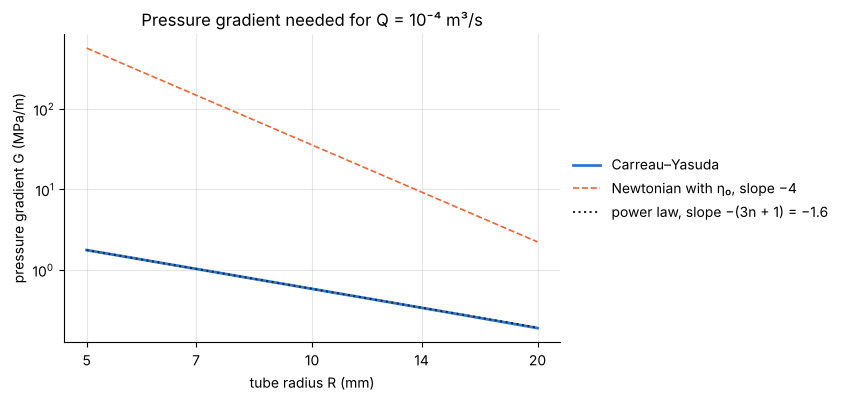

In [19]:
fig, ax = plt.subplots()
ax.loglog(radii * 1e3, G_needed / 1e6, label="Carreau–Yasuda")
ax.loglog(radii * 1e3, G_newton / 1e6, ls="--", lw=1.2, label="Newtonian with η₀, slope −4")
ax.loglog(radii * 1e3, G_power / 1e6, ls=":", lw=1.5, color="0.15", label="power law, slope −(3n + 1) = −1.6")
ax.set(xlabel="tube radius R (mm)", ylabel="pressure gradient G (MPa/m)",
       title="Pressure gradient needed for Q = 10⁻⁴ m³/s")
ax.set_xticks([5, 7, 10, 14, 20], labels=["5", "7", "10", "14", "20"])
ax.minorticks_off()
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

**Verify the slope.** There is an exact relation to test against. For a given fluid the apparent
shear rate $\dot\gamma_a = 4Q/(\pi R^3)$ depends only on the wall stress $\tau_w = GR/2$. Write
$N' = d\ln\dot\gamma_a/d\ln\tau_w$. At fixed $Q$, $d\ln\dot\gamma_a = -3\,d\ln R$ and
$d\ln\tau_w = d\ln G + d\ln R$, so

$$\frac{d\ln G}{d\ln R} = -\left(\frac{3}{N'} + 1\right),\qquad
N' = \frac{4\dot\gamma_w}{\dot\gamma_a} - 3 ,$$

where the second relation is the Weissenberg–Rabinowitsch correction of exercise 3. The right
side needs only the wall shear rate from `solve_pipe`, no differentiation.

In [20]:
gamma_wall = np.array([solve_pipe(G, R)["gamma_wall"] for G, R in zip(G_needed, radii)])
N_prime = 4 * gamma_wall / (4 * Q_fixed / (np.pi * radii**3)) - 3
predicted_slope = -(3 / N_prime + 1)

print(f"slope at R = 5 mm: {measured_slope[0]:.4f}    at R = 20 mm: {measured_slope[-1]:.4f}")
print(f"largest difference from the exact relation: {np.abs(measured_slope - predicted_slope).max():.1e}")
assert np.abs(measured_slope - predicted_slope).max() < 1e-6
power_law_slope = -(3 * fluid["n"] + 1)
assert np.all(measured_slope < power_law_slope) and np.all(measured_slope > power_law_slope - 0.1)
assert abs(measured_slope[0] - power_law_slope) < 1e-2

slope at R = 5 mm: -1.6004    at R = 20 mm: -1.6527
largest difference from the exact relation: 9.8e-11


**Answer.** The required pressure gradient falls from 1.76 MPa/m at $R = 5$ mm to 0.189 MPa/m at
$R = 20$ mm. On the log–log plot the slope is between $-1.60$ and $-1.65$, far from the Newtonian
$-4$: doubling the radius divides the pressure gradient by about 3, not by 16. The wall shear
rate is well above $1/\lambda$ at every radius, so the fluid is in its power-law regime, where
$Q \propto R^{3+1/n}G^{1/n}$ and therefore $G \propto R^{-(3n+1)} = R^{-1.6}$ at fixed $Q$.
Physically, a wider tube carries the same flow at a lower shear rate, and a shear-thinning fluid
becomes more viscous at a lower shear rate. That rise in viscosity cancels much of the
geometric benefit of the larger radius. The slope steepens slightly towards 20 mm because the
falling shear rate moves the fluid towards its Newtonian plateau, where the slope would be $-4$.